# Loan Payback Prediction

## About this Dataset
This dataset contains historical loan payback data useful for building and benchmarking regression and classification models.

In [3]:
import pandas as pd

df = pd.read_csv('dataset.csv')
df.head()

,age,gender,marital_status,education_level,annual_income,monthly_income,employment_status,debt_to_income_ratio,credit_score,loan_amount,...,loan_term,installment,grade_subgrade,num_of_open_accounts,total_credit_limit,current_balance,delinquency_history,public_records,num_of_delinquencies,loan_paid_back
0,59,Male,Married,Master's,24240.19,2020.02,Employed,0.074,743,17173.72,...,36,581.88,B5,7,40833.47,24302.07,1,0,1,1
1,72,Female,Married,Bachelor's,20172.98,1681.08,Employed,0.219,531,22663.89,...,60,573.17,F1,5,27968.01,10803.01,1,0,3,1
2,49,Female,Single,High School,26181.80,2181.82,Employed,0.234,779,3631.36,...,60,76.32,B4,2,15502.25,4505.44,0,0,0,1
3,35,Female,Single,High School,11873.84,989.49,Employed,0.264,809,14939.23,...,36,468.07,A5,7,18157.79,5525.63,4,0,5,1
4,63,Other,Single,Other,25326.44,2110.54,Employed,0.260,663,16551.71,...,60,395.50,D5,1,17467.56,3593.91,2,0,2,1


In [4]:
duplicates_before = df.duplicated().sum()
df = df.drop_duplicates()
print(f'Removed {duplicates_before} duplicate rows.')

Removed 0 duplicate rows.


In [5]:
print(df.isnull().sum())

age                     0
gender                  0
marital_status          0
education_level         0
annual_income           0
monthly_income          0
employment_status       0
debt_to_income_ratio    0
credit_score            0
loan_amount             0
loan_purpose            0
interest_rate           0
loan_term               0
installment             0
grade_subgrade          0
num_of_open_accounts    0
total_credit_limit      0
current_balance         0
delinquency_history     0
public_records          0
num_of_delinquencies    0
loan_paid_back          0
dtype: int64


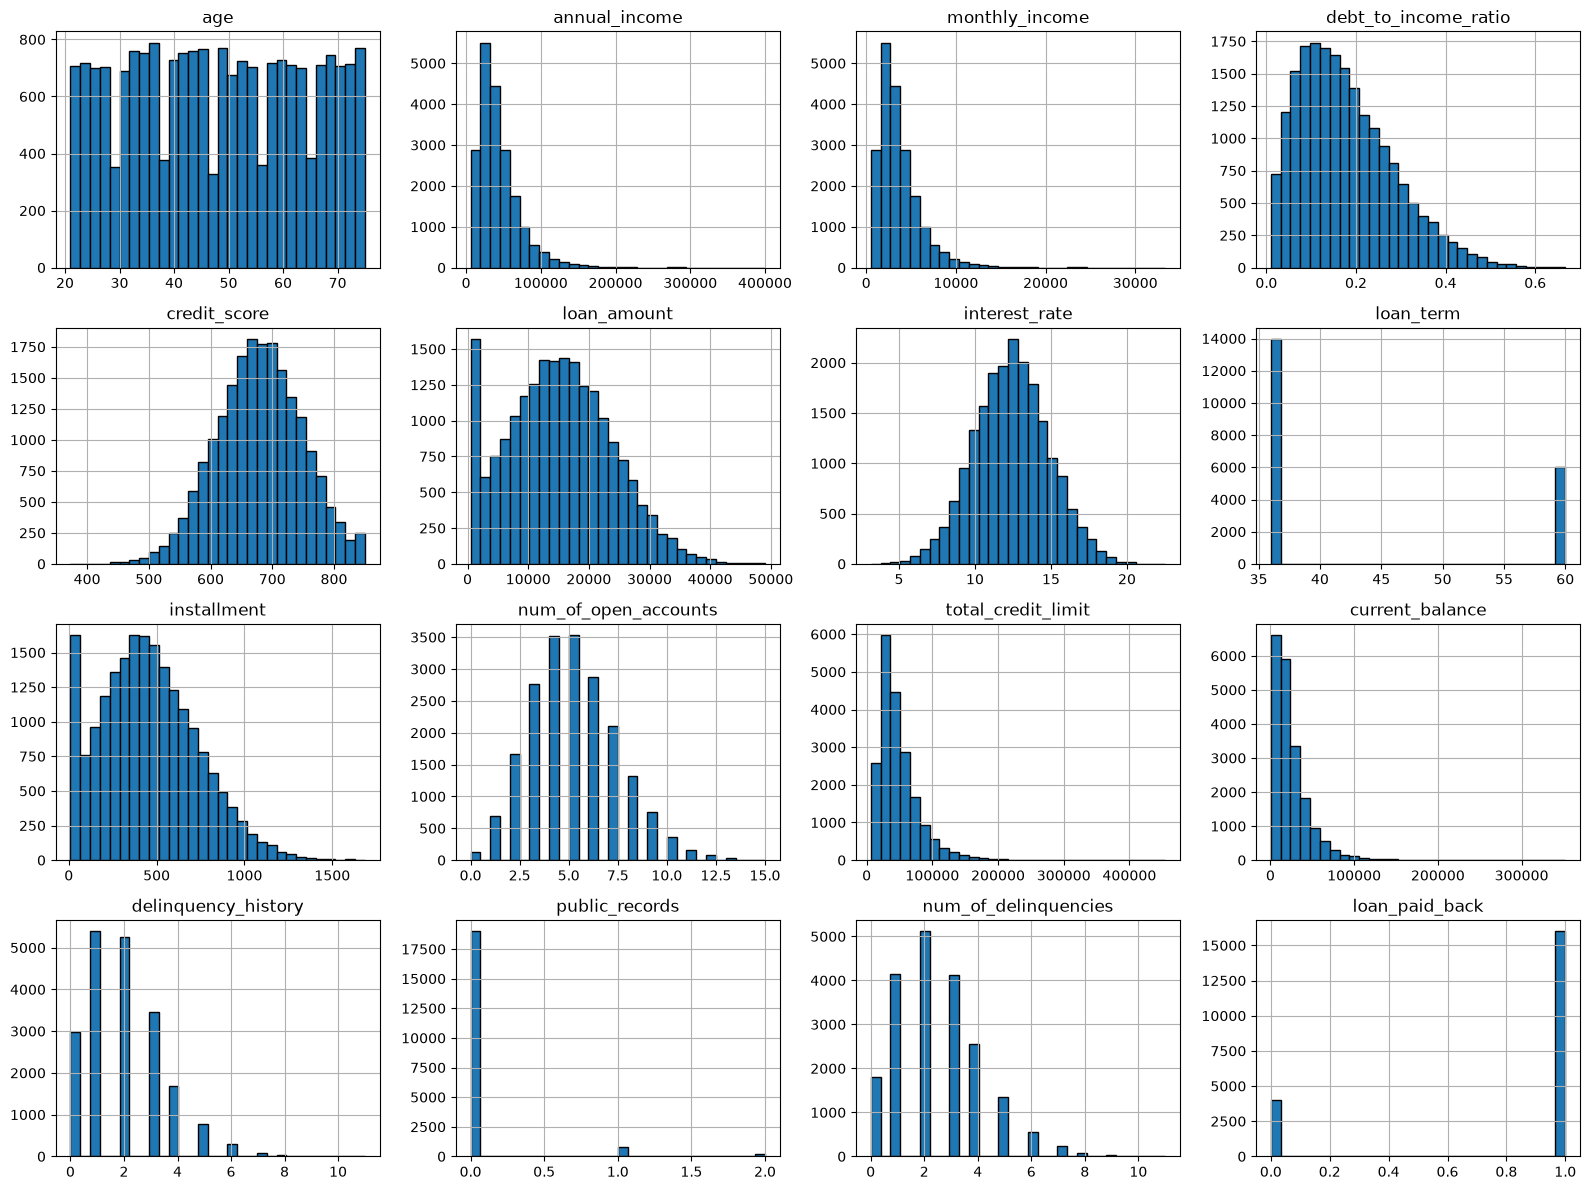

In [6]:
import matplotlib.pyplot as plt
numeric_columns = df.select_dtypes(include='number').columns
df[numeric_columns].hist(figsize=(16, 12), bins=30, edgecolor="black")
plt.tight_layout()
plt.show()

In [7]:
from sklearn.model_selection import train_test_split

target_column = 'loan_paid_back'
X = df.drop(columns=[target_column])
y = df[target_column]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
print(f"Training rows: {len(X_train)} ({len(X_train) / len(df):.0%})")
print(f"Test rows: {len(X_test)} ({len(X_test) / len(df):.0%})")

Training rows: 14000 (70%)
Test rows: 6000 (30%)


In [8]:
from sklearn.preprocessing import OrdinalEncoder

categorical_columns = X_train.select_dtypes(include=['object', 'category', 'string']).columns
feature_columns = X_train.columns.tolist()
label_encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)

if len(categorical_columns) > 0:
    encoded_train = pd.DataFrame(
        label_encoder.fit_transform(X_train[categorical_columns]),
        columns=categorical_columns,
        index=X_train.index
    )
    encoded_test = pd.DataFrame(
        label_encoder.transform(X_test[categorical_columns]),
        columns=categorical_columns,
        index=X_test.index
    )
    X_train = X_train.drop(columns=categorical_columns).join(encoded_train)
    X_test = X_test.drop(columns=categorical_columns).join(encoded_test)
    X_train = X_train.reindex(columns=feature_columns)
    X_test = X_test.reindex(columns=feature_columns)

print(f"Label-encoded {len(categorical_columns)} categorical feature columns:")
print(list(categorical_columns))

Label-encoded 6 categorical feature columns:
['gender', 'marital_status', 'education_level', 'employment_status', 'loan_purpose', 'grade_subgrade']


In [9]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)
X_test = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"Test accuracy: {accuracy:.4f}")

Test accuracy: 0.8860


In [11]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"F1 score:  {f1_score(y_test, y_pred, zero_division=0):.4f}")
print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy:  0.8860
Precision: 0.8964
Recall:    0.9696
F1 score:  0.9315

Confusion matrix:
[[ 663  538]
 [ 146 4653]]

Classification report:
              precision    recall  f1-score   support

           0       0.82      0.55      0.66      1201
           1       0.90      0.97      0.93      4799

    accuracy                           0.89      6000
   macro avg       0.86      0.76      0.80      6000
weighted avg       0.88      0.89      0.88      6000



In [12]:
import pandas as pd
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    AdaBoostClassifier,
)
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=42),
    "AdaBoost": AdaBoostClassifier(random_state=42),
    "Gaussian Naive Bayes": GaussianNB(),
    "Linear SVM": LinearSVC(random_state=42),
}

comparison_rows = []
trained_models = {}

for name, estimator in models.items():
    pipeline = Pipeline([("classifier", clone(estimator))])
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)
    classifier = pipeline.named_steps["classifier"]

    if hasattr(classifier, "predict_proba"):
        scores = pipeline.predict_proba(X_test)[:, 1]
    elif hasattr(classifier, "decision_function"):
        scores = pipeline.decision_function(X_test)
    else:
        scores = None

    tn, fp, fn, tp = confusion_matrix(y_test, predictions, labels=[0, 1]).ravel()
    comparison_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Balanced Accuracy": balanced_accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, scores) if scores is not None else float("nan"),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
    })
    trained_models[name] = pipeline

comparison = pd.DataFrame(comparison_rows).sort_values("Accuracy", ascending=False).reset_index(drop=True)
print(comparison.round(4).to_string(index=False))

                 Model  Accuracy  Balanced Accuracy  Precision  Recall     F1  ROC-AUC  TN  FP  FN   TP
Hist Gradient Boosting    0.9035             0.7671     0.8962  0.9946 0.9428   0.8891 648 553  26 4773
     Gradient Boosting    0.9032             0.7694     0.8973  0.9925 0.9425   0.8878 656 545  36 4763
         Random Forest    0.9015             0.7643     0.8952  0.9931 0.9416   0.8684 643 558  33 4766
           Extra Trees    0.8968             0.7567     0.8924  0.9904 0.9389   0.8698 628 573  46 4753
              AdaBoost    0.8882             0.7709     0.9009  0.9665 0.9325   0.8736 691 510 161 4638
            Linear SVM    0.8877             0.7619     0.8966  0.9717 0.9326   0.8440 663 538 136 4663
   Logistic Regression    0.8860             0.7608     0.8964  0.9696 0.9315   0.8466 663 538 146 4653
   K-Nearest Neighbors    0.8568             0.6917     0.8688  0.9671 0.9153   0.7706 500 701 158 4641
  Gaussian Naive Bayes    0.8523             0.7572     0.9012  

In [13]:
import pandas as pd
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
}

cv_rows = []
for name, estimator in models.items():
    pipeline = Pipeline([("classifier", clone(estimator))])
    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1,
        error_score="raise",
    )
    row = {"Model": name}
    for metric in scoring:
        row[f"{metric.replace('_', ' ').title()} Mean"] = scores[f"test_{metric}"].mean()
        row[f"{metric.replace('_', ' ').title()} Std"] = scores[f"test_{metric}"].std()
    cv_rows.append(row)

cv_comparison = pd.DataFrame(cv_rows).sort_values(
    "Balanced Accuracy Mean", ascending=False
).reset_index(drop=True)
print("5-fold cross-validation results (ranked by balanced accuracy):")
print(cv_comparison.round(4).to_string(index=False))

best_model_name = cv_comparison.loc[0, "Model"]
final_model = Pipeline([("classifier", clone(models[best_model_name]))])
final_model.fit(X_train, y_train)
test_predictions = final_model.predict(X_test)
test_scores = final_model.predict_proba(X_test)[:, 1] if hasattr(final_model.named_steps["classifier"], "predict_proba") else final_model.decision_function(X_test)

tn, fp, fn, tp = confusion_matrix(y_test, test_predictions, labels=[0, 1]).ravel()
print(f"\nSelected by cross-validation: {best_model_name}")
print(f"Test accuracy:          {accuracy_score(y_test, test_predictions):.4f}")
print(f"Test balanced accuracy: {balanced_accuracy_score(y_test, test_predictions):.4f}")
print(f"Test precision:         {precision_score(y_test, test_predictions, zero_division=0):.4f}")
print(f"Test recall:            {recall_score(y_test, test_predictions, zero_division=0):.4f}")
print(f"Test F1:                {f1_score(y_test, test_predictions, zero_division=0):.4f}")
print(f"Test ROC-AUC:           {roc_auc_score(y_test, test_scores):.4f}")
print(f"Test confusion matrix [ [TN, FP], [FN, TP] ]: [[{tn}, {fp}], [{fn}, {tp}]]")
print("\nTest classification report:")
print(classification_report(y_test, test_predictions, zero_division=0))

5-fold cross-validation results (ranked by balanced accuracy):
                 Model  Accuracy Mean  Accuracy Std  Balanced Accuracy Mean  Balanced Accuracy Std  Precision Mean  Precision Std  Recall Mean  Recall Std  F1 Mean  F1 Std  Roc Auc Mean  Roc Auc Std
              AdaBoost         0.8886        0.0059                  0.7664                 0.0147          0.8987         0.0062       0.9702      0.0037   0.9331  0.0033        0.8732       0.0114
     Gradient Boosting         0.9009        0.0056                  0.7656                 0.0134          0.8960         0.0054       0.9911      0.0010   0.9412  0.0032        0.8906       0.0119
            Linear SVM         0.8885        0.0076                  0.7653                 0.0176          0.8982         0.0072       0.9707      0.0021   0.9330  0.0044        0.8505       0.0132
  Gaussian Naive Bayes         0.8565        0.0082                  0.7649                 0.0169          0.9045         0.0076       0.917

In [14]:
import numpy as np
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

threshold_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
threshold_model = Pipeline([("classifier", clone(models[best_model_name]))])
oof_probabilities = cross_val_predict(
    threshold_model,
    X_train,
    y_train,
    cv=threshold_cv,
    method="predict_proba",
    n_jobs=1,
)[:, 1]

thresholds = np.arange(0.05, 0.96, 0.01)
threshold_results = []
for threshold in thresholds:
    oof_predictions = (oof_probabilities >= threshold).astype(int)
    threshold_results.append((
        threshold,
        balanced_accuracy_score(y_train, oof_predictions),
        recall_score(y_train, oof_predictions, pos_label=0, zero_division=0),
    ))

best_threshold, best_cv_balanced_accuracy, best_cv_recall_nonrepay = max(
    threshold_results, key=lambda row: (row[1], row[2])
)

final_model.fit(X_train, y_train)
test_probabilities = final_model.predict_proba(X_test)[:, 1]
default_predictions = (test_probabilities >= 0.50).astype(int)
tuned_predictions = (test_probabilities >= best_threshold).astype(int)

print(f"Selected model: {best_model_name}")
print(f"OOF-selected threshold: {best_threshold:.2f}")
print(f"OOF balanced accuracy at threshold: {best_cv_balanced_accuracy:.4f}")
print(f"OOF recall for non-repayment (class 0): {best_cv_recall_nonrepay:.4f}")

for label, predictions in [("Default threshold (0.50)", default_predictions), (f"Tuned threshold ({best_threshold:.2f})", tuned_predictions)]:
    print(f"\n{label}")
    print(f"Balanced accuracy: {balanced_accuracy_score(y_test, predictions):.4f}")
    print(f"Class 0 (not repaid) precision: {precision_score(y_test, predictions, pos_label=0, zero_division=0):.4f}")
    print(f"Class 0 (not repaid) recall:    {recall_score(y_test, predictions, pos_label=0, zero_division=0):.4f}")
    print(f"Class 0 (not repaid) F1:        {f1_score(y_test, predictions, pos_label=0, zero_division=0):.4f}")
    print("Confusion matrix [rows=true 0,1; columns=predicted 0,1]:")
    print(confusion_matrix(y_test, predictions, labels=[0, 1]))
    print(classification_report(y_test, predictions, labels=[0, 1], target_names=["Not repaid (0)", "Repaid (1)"], zero_division=0))

Selected model: AdaBoost
OOF-selected threshold: 0.54
OOF balanced accuracy at threshold: 0.7784
OOF recall for non-repayment (class 0): 0.6473

Default threshold (0.50)
Balanced accuracy: 0.7709
Class 0 (not repaid) precision: 0.8110
Class 0 (not repaid) recall:    0.5754
Class 0 (not repaid) F1:        0.6732
Confusion matrix [rows=true 0,1; columns=predicted 0,1]:
[[ 691  510]
 [ 161 4638]]
                precision    recall  f1-score   support

Not repaid (0)       0.81      0.58      0.67      1201
    Repaid (1)       0.90      0.97      0.93      4799

      accuracy                           0.89      6000
     macro avg       0.86      0.77      0.80      6000
  weighted avg       0.88      0.89      0.88      6000


Tuned threshold (0.54)
Balanced accuracy: 0.7827
Class 0 (not repaid) precision: 0.6203
Class 0 (not repaid) recall:    0.6678
Class 0 (not repaid) F1:        0.6431
Confusion matrix [rows=true 0,1; columns=predicted 0,1]:
[[ 802  399]
 [ 491 4308]]
             

In [15]:
import numpy as np
from scipy.stats import randint, loguniform
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, cross_val_predict
from sklearn.metrics import (
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

# Tune AdaBoost using training data only; balanced accuracy accounts for class imbalance.
tuning_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
ada_pipeline = Pipeline([
    ("classifier", AdaBoostClassifier(
        estimator=DecisionTreeClassifier(random_state=42),
        random_state=42,
    ))
])
parameter_distributions = {
    "classifier__n_estimators": randint(50, 301),
    "classifier__learning_rate": loguniform(0.01, 1.0),
    "classifier__estimator__max_depth": [1, 2, 3],
    "classifier__estimator__min_samples_leaf": [1, 2, 5],
}

ada_search = RandomizedSearchCV(
    estimator=ada_pipeline,
    param_distributions=parameter_distributions,
    n_iter=20,
    scoring="balanced_accuracy",
    cv=tuning_cv,
    random_state=42,
    n_jobs=-1,
    refit=True,
    verbose=1,
)
ada_search.fit(X_train, y_train)
tuned_model = ada_search.best_estimator_
print(f"Best cross-validated balanced accuracy: {ada_search.best_score_:.4f}")
print("Best AdaBoost parameters:")
print(ada_search.best_params_)

# Choose the classification threshold from out-of-fold training probabilities.
oof_probabilities = cross_val_predict(
    clone(tuned_model),
    X_train,
    y_train,
    cv=tuning_cv,
    method="predict_proba",
    n_jobs=-1,
)[:, 1]
thresholds = np.arange(0.05, 0.96, 0.01)
threshold_results = []
for threshold in thresholds:
    oof_predictions = (oof_probabilities >= threshold).astype(int)
    threshold_results.append((
        threshold,
        balanced_accuracy_score(y_train, oof_predictions),
        recall_score(y_train, oof_predictions, pos_label=0, zero_division=0),
    ))
best_threshold, threshold_cv_score, threshold_recall_nonrepay = max(
    threshold_results, key=lambda row: (row[1], row[2])
)
print(f"\nSelected threshold: {best_threshold:.2f}")
print(f"OOF balanced accuracy at selected threshold: {threshold_cv_score:.4f}")
print(f"OOF recall for non-repayment (class 0): {threshold_recall_nonrepay:.4f}")

# Compare thresholds on the test set for reference; the test set was used earlier in exploration.
test_probabilities = tuned_model.predict_proba(X_test)[:, 1]
for label, threshold in [("Default", 0.50), ("Tuned", best_threshold)]:
    predictions = (test_probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, predictions, labels=[0, 1]).ravel()
    print(f"\n{label} threshold ({threshold:.2f})")
    print(f"Balanced accuracy: {balanced_accuracy_score(y_test, predictions):.4f}")
    print(f"Class 0 precision: {precision_score(y_test, predictions, pos_label=0, zero_division=0):.4f}")
    print(f"Class 0 recall:    {recall_score(y_test, predictions, pos_label=0, zero_division=0):.4f}")
    print(f"Class 0 F1:        {f1_score(y_test, predictions, pos_label=0, zero_division=0):.4f}")
    print(f"Confusion matrix [rows=true 0,1; columns=predicted 0,1]: [[{tn}, {fp}], [{fn}, {tp}]]")

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best cross-validated balanced accuracy: 0.7663
Best AdaBoost parameters:
{'classifier__estimator__max_depth': 3, 'classifier__estimator__min_samples_leaf': 1, 'classifier__learning_rate': np.float64(0.46386309723972763), 'classifier__n_estimators': 84}

Selected threshold: 0.60
OOF balanced accuracy at selected threshold: 0.7852
OOF recall for non-repayment (class 0): 0.7358

Default threshold (0.50)
Balanced accuracy: 0.7686
Class 0 precision: 0.9230
Class 0 recall:    0.5487
Class 0 F1:        0.6883
Confusion matrix [rows=true 0,1; columns=predicted 0,1]: [[659, 542], [55, 4744]]

Tuned threshold (0.60)
Balanced accuracy: 0.7914
Class 0 precision: 0.5288
Class 0 recall:    0.7502
Class 0 F1:        0.6203
Confusion matrix [rows=true 0,1; columns=predicted 0,1]: [[901, 300], [803, 3996]]


### Choosing a threshold

At 0.50, the model marked 55 repaid loans as not repaid. At 0.60, it marked 803 repaid loans that way, but it also caught more loans that actually were not repaid: 901 instead of 659.

Use 0.60 if catching more non-repayments matters most. Use 0.50 if you want fewer false alarms. Which one makes sense depends on which mistake is more costly.

## Save model bundle

Run this cell after tuning to save the fitted model, preprocessing steps, and prediction threshold for the FastAPI and Streamlit apps.

In [101]:
import pickle
from pathlib import Path
import sklearn

# Save the fitted preprocessing steps, model, feature order, and selected threshold together.
artifact_dir = Path("Train_model")
if not artifact_dir.exists():
    artifact_dir = Path(".")
artifact_path = artifact_dir / "model_bundle.pkl"

model_bundle = {
    "model": tuned_model,
    "encoder": label_encoder,
    "categorical_columns": list(categorical_columns),
    "feature_columns": list(feature_columns),
    "scaler": scaler,
    "threshold": float(best_threshold),
    "sklearn_version": sklearn.__version__,
    "feature_defaults": {
        column: (str(df[column].mode(dropna=True).iloc[0]) if column in categorical_columns else float(df[column].median()))
        for column in feature_columns
    },
}

with artifact_path.open("wb") as file:
    pickle.dump(model_bundle, file)

print(f"Saved model bundle to: {artifact_path.resolve()}")
print(f"Prediction threshold: {best_threshold:.2f}")

Saved model bundle to: C:\Users\ISHVARYA KALYANKUMAR\projects\Loan-prediction-system\Train_model\model_bundle.pkl
Prediction threshold: 0.60
